# 이상치 상세 분석 보고서 (Context 포함)

이 보고서는 `find_outliers.py`를 통해 추출된 이상치(Internal Speed, Gap Speed 과속)와 그 전후 문맥(Context) 데이터를 분석합니다.
단순히 어떤 이벤트가 이상치인지 파악하는 것을 넘어, **전후 상황(이전 이벤트, 다음 이벤트)**을 함께 살펴봄으로써 이상치 발생의 원인을 규명하는 데 목적이 있습니다.

## 데이터 로드
- 데이터 소스: `data/refined/v5.3/preprocessed_data_outliers.csv`
- 구성: 이상치(Target) 이벤트와 해당 이벤트의 직전(Prev), 직후(Next) 데이터가 함께 저장되어 있습니다.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (Windows 기준)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

In [25]:
# 데이터 로드
file_path = '../data/refined/v5.3/preprocessed_data_outliers.csv'
df = pd.read_csv(file_path)

print(f"Loaded {len(df):,} rows.")
display(df.head())

Loaded 15,630 rows.


,ref_action_id,context_role,context_offset,outlier_type,game_id,period_id,time_seconds,team_id,player_name_ko,action_id,type_name,result_name,start_x,start_y,end_x,end_y,internal_speed,gap_speed,dx,dy,dt_to_next,gap_dist,gap_dt
0,134,prev,-2,NaN,126283,1,254.301,2354,고승범,132,Carry,NaN,0.255852,0.324033,0.316054,0.383933,5.140044,0.000000,0.060202,0.059900,1.463,0.000000,0.001
1,134,prev,-1,NaN,126283,1,255.764,4639,한찬희,133,Tackle,Unsuccessful,0.313967,0.391289,0.313967,0.391289,0.000000,0.373276,0.000000,0.000000,0.003,0.546103,1.463
2,134,target,0,Gap,126283,1,255.767,2354,고승범,134,Pass,Successful,0.316054,0.383933,0.387497,0.332881,8.547933,182.034243,0.071443,-0.051052,0.967,0.546103,0.003
3,134,next,1,NaN,126283,1,256.734,2354,아타루,136,Carry,NaN,0.387497,0.332881,0.383846,0.284812,3.185959,0.000000,-0.003651,-0.048069,1.033,0.000000,0.967
4,134,next,2,NaN,126283,1,257.767,4639,박찬용,137,Foul,NaN,0.383846,0.284812,0.383846,0.284812,0.000000,0.000000,0.000000,0.000000,23.466,0.000000,1.033


## 1. 이상치 현황 요약
분석 대상은 `context_role`이 'target'인 행들입니다. 이를 통해 전체적인 이상치 분포를 먼저 확인합니다.

C:\Users\user\AppData\Local\Temp\ipykernel_16168\1686899341.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=type_counts.index, y=type_counts.values, palette='viridis')


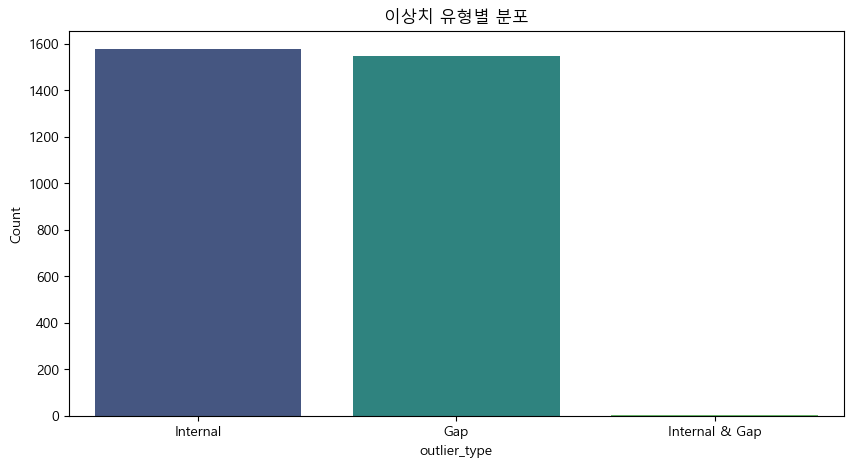

=== 이상치 유형별 통계 ===
outlier_type
Internal          1577
Gap               1547
Internal & Gap       2
Name: count, dtype: int64


In [26]:
# Target 데이터만 필터링
target_df = df[df['context_role'] == 'target'].copy()

# 이상치 유형별 카운트
type_counts = target_df['outlier_type'].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=type_counts.index, y=type_counts.values, palette='viridis')
plt.title('이상치 유형별 분포')
plt.ylabel('Count')
plt.show()

print("=== 이상치 유형별 통계 ===")
print(type_counts)

C:\Users\user\AppData\Local\Temp\ipykernel_16168\4140836358.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=game_counts.index.astype(str), y=game_counts.values, palette='Reds_r')


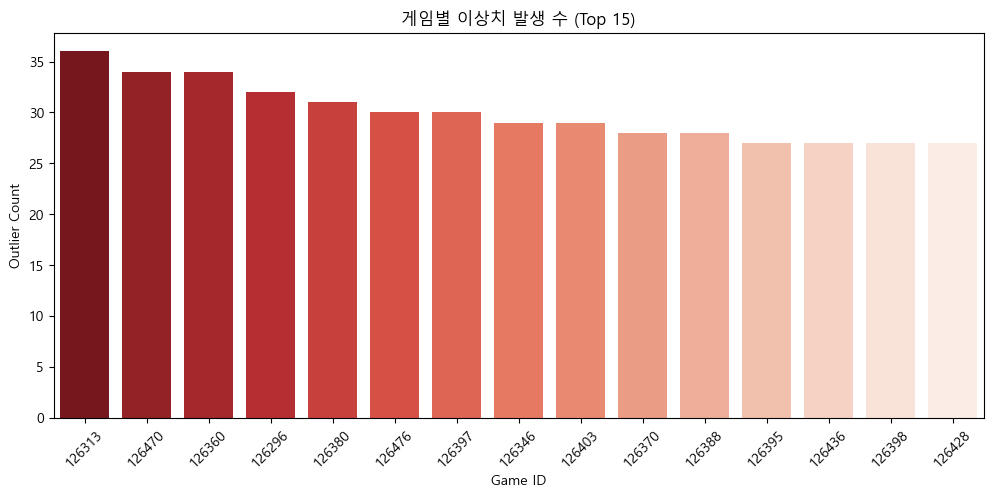

In [27]:
# 게임별 이상치 발생 빈도 (Top 15)
game_counts = target_df['game_id'].value_counts().head(15)

plt.figure(figsize=(12, 5))
sns.barplot(x=game_counts.index.astype(str), y=game_counts.values, palette='Reds_r')
plt.title('게임별 이상치 발생 수 (Top 15)')
plt.xlabel('Game ID')
plt.ylabel('Outlier Count')
plt.xticks(rotation=45)
plt.show()

## 2. 상세 문맥 분석 (Context Inspection)

각 이상치 케이스에 대해 **이전(Prev) -> 대상(Target) -> 다음(Next)** 이벤트의 흐름을 확인합니다.
좌표는 이해를 돕기 위해 0~1 정규화된 값을 **105m x 68m** 실제 규격으로 변환하여 표시합니다.

### 2-1. Internal Speed 과속 상위 10개 케이스
단일 이벤트 내에서 말도 안 되는 속도가 찍힌 경우입니다. (예: 드리블 중 순간이동 등)

In [28]:
def display_context_cases(target_df, full_df, sort_col, top_n=10):
    """
    특정 기준(sort_col)으로 정렬된 상위 top_n개 이상치에 대해 문맥(Context)을 출력합니다.
    """
    # 상위 케이스 추출
    top_cases = target_df.sort_values(sort_col, ascending=False).head(top_n)
    
    for i, (_, row) in enumerate(top_cases.iterrows()):
        ref_id = row['ref_action_id']
        
        # 해당 그룹의 전체 데이터(Prev, Target, Next) 가져오기
        context_group = full_df[full_df['ref_action_id'] == ref_id].sort_values('time_seconds')
        
        # 좌표 스케일링 (105x68)
        display_cols = [
            'context_role', 'type_name', 'player_name_ko', 
            'time_seconds', 'dt_to_next', 
            'start_x', 'start_y', 'end_x', 'end_y', 
            'internal_speed', 'gap_speed'
        ]
        
        view_df = context_group[display_cols].copy()
        
        # 미터 단위 변환 (원본이 0~1이라고 가정하고 저장된 데이터가 이미 정규화된 상태일 수 있으므로)
        # 주의: find_outliers.py 저장 시 좌표는 원본 값 그대로 저장됨.
        # 만약 원본이 0~1이었다면 여기서 곱해줌. (find_outliers 실행 로그 보면 Normalized: True 였음)
        view_df[['start_x', 'end_x']] *= 105.0
        view_df[['start_y', 'end_y']] *= 68.0
        
        # 포맷팅
        print(f"\n[{i+1}/{top_n}] Game: {row['game_id']} | Period: {row['period_id']} | Ref Action ID: {ref_id}")
        print(f"Main Issue: {sort_col} = {row[sort_col]:.2f} m/s")
        
        # 스타일링하여 출력
        styled = view_df.style.apply(
            lambda x: ['background-color: #ffcccc; color: black' if x['context_role'] == 'target' else '' for _ in x], 
            axis=1
        ).format({
            'start_x': '{:.1f}', 'start_y': '{:.1f}', 
            'end_x': '{:.1f}', 'end_y': '{:.1f}',
            'time_seconds': '{:.2f}', 'dt_to_next': '{:.3f}',
            'internal_speed': '{:.1f}', 'gap_speed': '{:.1f}'
        })
        display(styled)

In [29]:
# Internal Speed 상위 10개 조회
internal_outliers = target_df[target_df['outlier_type'].str.contains('Internal')]
display_context_cases(internal_outliers, df, 'internal_speed', top_n=10)


[1/10] Game: 126416 | Period: 1 | Ref Action ID: 375
Main Issue: internal_speed = 33705.92 m/s


,context_role,type_name,player_name_ko,time_seconds,dt_to_next,start_x,start_y,end_x,end_y,internal_speed,gap_speed
10485,prev,Carry,황문기,662.83,1.499,31.5,62.0,26.8,63.9,3.4,0.0
10486,prev,Foul,박정인,664.33,47.496,26.8,63.9,26.8,63.9,0.0,0.0
10487,target,Pass_Freekick,김강국,711.83,0.001,25.4,65.1,16.0,32.7,33705.9,0.0
10488,next,Foul,김영빈,711.83,10.970,16.0,32.7,16.0,32.7,0.0,0.0
10489,next,Pass_Freekick,이창근,722.80,1.568,4.0,48.5,14.6,57.2,8.8,1.8



[2/10] Game: 126336 | Period: 1 | Ref Action ID: 1124
Main Issue: internal_speed = 5271.64 m/s


,context_role,type_name,player_name_ko,time_seconds,dt_to_next,start_x,start_y,end_x,end_y,internal_speed,gap_speed
4180,prev,Pass,황석호,2298.66,2.723,25.7,40.7,3.0,33.9,8.7,nan
4181,prev,Pass,조현우,2301.38,3.012,3.0,33.9,19.3,62.9,11.1,0.0
4182,target,Clearance,심상민,2304.39,0.006,19.3,62.9,50.3,56.3,5271.6,0.0
4183,next,Tackle,유리 조나탄,2304.40,6.025,18.9,61.0,18.9,61.0,0.0,5288.7
4184,next,Recovery,켈빈,2310.43,0.001,50.3,56.3,50.3,56.3,0.0,5.3



[3/10] Game: 126469 | Period: 1 | Ref Action ID: 453
Main Issue: internal_speed = 5169.74 m/s


...

,context_role,type_name,player_name_ko,time_seconds,dt_to_next,start_x,start_y,end_x,end_y,internal_speed,gap_speed
10720,prev,Interception,안데르손,631.77,0.001,68.9,48.0,68.9,48.0,0.0,nan
10721,prev,Carry,안데르손,631.77,3.899,68.9,48.0,81.9,45.9,3.4,0.0
10722,target,Shot,안데르손,635.67,0.001,81.9,45.9,83.8,43.9,2712.7,0.0
10723,next,Block,박진영,635.67,1.865,83.8,43.9,83.8,43.9,0.0,0.0
10724,next,Recovery,정승원,637.53,0.001,89.7,27.4,89.7,27.4,0.0,9.4



[9/10] Game: 126468 | Period: 2 | Ref Action ID: 1588
Main Issue: internal_speed = 2374.70 m/s


,context_role,type_name,player_name_ko,time_seconds,dt_to_next,start_x,start_y,end_x,end_y,internal_speed,gap_speed
14485,prev,Out,김준홍,363.37,12.125,60.7,0.0,60.7,0.0,0.0,0.2
14486,prev,Throw-In,김문환,375.49,1.038,60.7,0.0,69.9,2.1,9.1,0.0
14487,target,Pass,김준범,376.53,0.003,69.9,2.1,68.4,9.1,2374.7,0.0
14488,next,Tackle,김태현,376.53,1.067,70.2,3.2,70.2,3.2,0.0,2059.9
14489,next,Carry,김승대,377.60,1.303,68.4,9.1,68.9,11.8,0.0,5.8



[10/10] Game: 126336 | Period: 1 | Ref Action ID: 1568
Main Issue: internal_speed = 2284.26 m/s


,context_role,type_name,player_name_ko,time_seconds,dt_to_next,start_x,start_y,end_x,end_y,internal_speed,gap_speed
13120,prev,Tackle,박대원,488.13,0.634,19.0,67.4,19.0,67.4,0.0,0.0
13121,prev,Pass,김현욱,488.77,0.033,19.9,67.5,20.3,63.3,129.9,1.5
13122,target,Tackle,김대원,488.80,0.967,20.1,67.2,20.1,67.2,0.0,119.6
13123,next,Tackle,박대원,489.77,0.230,19.6,63.8,19.6,63.8,0.0,3.6
13124,next,Pass,김문환,490.00,1.457,20.3,63.3,18.5,57.6,4.1,3.9
4190,prev,Pass,주민규,2985.88,2.158,54.4,49.5,64.6,62.3,7.6,0.0
4191,prev,Carry,켈빈,2988.03,3.257,64.6,62.3,75.6,63.1,3.4,0.0
4192,target,Pass,켈빈,2991.29,0.009,75.6,63.1,56.9,54.5,2284.3,0.0
4193,next,Tackle,김태환,2991.30,3.250,75.9,62.3,75.9,62.3,0.0,2280.1
4194,next,Carry,심상민,2994.55,3.195,56.9,54.5,68.0,56.5,3.5,6.3


### 2-2. Gap Speed 과속 상위 10개 케이스
이전 이벤트 종료 후 현재 이벤트 시작 사이에 비정상적인 이동(순간이동)이 발생한 경우입니다.
주로 데이터 누락이나 카메라 시점 전환 등으로 인해 발생할 수 있습니다.

In [ ]:
# Gap Speed 상위 10개 조회
gap_outliers = target_df[target_df['outlier_type'].str.contains('Gap')]
display_context_cases(gap_outliers, df, 'gap_speed', top_n=10)


[1/10] Game: 126302 | Period: 2 | Ref Action ID: 2465
Main Issue: gap_speed = 9572.35 m/s


,context_role,type_name,player_name_ko,time_seconds,dt_to_next,start_x,start_y,end_x,end_y,internal_speed,gap_speed
1505,prev,Cross,김인균,2163.13,1.133,10.4,60.9,6.6,37.8,20.6,0.0
1506,prev,Offside,아론,2164.27,0.001,3.6,28.7,3.6,28.7,0.0,8.4
1507,target,Duel,안톤,2164.27,0.000,6.6,37.8,3.6,28.7,nan,9572.3
1508,next,Pass,안톤,2164.27,41.666,6.6,37.8,3.6,28.7,0.2,nan
1509,next,Pass_Freekick,이범수,2205.93,3.000,10.8,39.5,68.1,26.8,19.6,0.3



[2/10] Game: 126469 | Period: 1 | Ref Action ID: 454
Main Issue: gap_speed = 5641.33 m/s


,context_role,type_name,player_name_ko,time_seconds,dt_to_next,start_x,start_y,end_x,end_y,internal_speed,gap_speed
14530,prev,Duel,무고사,944.77,0.000,63.4,24.5,66.3,20.2,nan,0.0
14531,prev,Pass,무고사,944.77,0.001,63.4,24.5,66.3,20.2,5169.7,nan
14532,target,Tackle,전민광,944.77,1.399,63.0,24.8,63.0,24.8,0.0,5641.3
14533,next,Pass,신진호,946.17,3.301,66.3,20.2,55.6,49.4,9.4,4.0
14534,next,Duel,완델손,949.47,0.000,55.9,50.7,55.9,50.7,nan,0.4
825,prev,Carry,이희균,1001.20,0.033,49.3,15.1,49.5,14.9,0.0,11.9
826,prev,Take-On,이희균,1001.23,0.001,49.5,14.9,49.5,14.9,0.0,0.0
827,target,Carry,이희균,1001.23,0.033,49.5,14.9,54.0,13.1,146.6,0.0
828,next,Tackle,윤석영,1001.27,1.066,49.8,13.9,49.8,13.9,0.0,130.2
829,next,Tackle,양민혁,1002.33,0.000,54.0,13.1,54.0,13.1,nan,4.0



[3/10] Game: 126336 | Period: 1 | Ref Action ID: 1125
Main Issue: gap_speed = 5288.75 m/s


...


[9/10] Game: 126350 | Period: 1 | Ref Action ID: 110
Main Issue: gap_speed = 2295.91 m/s


,context_role,type_name,player_name_ko,time_seconds,dt_to_next,start_x,start_y,end_x,end_y,internal_speed,gap_speed
8580,prev,Carry,강성진,175.40,1.300,42.2,13.1,43.0,15.5,0.0,0.0
8581,prev,Pass,강성진,176.70,0.133,43.0,15.5,56.4,39.9,209.4,0.0
8582,target,Tackle,김대우,176.83,1.501,43.8,16.7,43.8,16.7,0.0,198.5
8583,next,Carry,윌리안,178.33,2.366,56.4,39.9,57.1,31.9,3.4,17.6
8584,next,Pass,윌리안,180.70,2.001,57.1,31.9,76.7,6.3,16.1,0.0
12645,prev,Take-On,윤민호,186.83,0.001,58.1,10.7,58.1,10.7,0.0,0.0
12646,prev,Carry,윤민호,186.83,0.233,58.1,10.7,86.4,7.4,122.2,0.0
12647,target,Tackle,장성원,187.07,4.737,59.0,11.0,59.0,11.0,0.0,118.3
5095,prev,Carry,이강현,188.52,1.902,31.8,17.5,33.2,20.4,1.7,0.0
5096,prev,Pass,이강현,190.42,0.015,33.2,20.4,47.8,51.2,2271.2,0.0



[10/10] Game: 126336 | Period: 1 | Ref Action ID: 1569
Main Issue: gap_speed = 2280.10 m/s


,context_role,type_name,player_name_ko,time_seconds,dt_to_next,start_x,start_y,end_x,end_y,internal_speed,gap_speed
4195,prev,Carry,켈빈,2988.03,3.257,64.6,62.3,75.6,63.1,3.4,0.0
4196,prev,Pass,켈빈,2991.29,0.009,75.6,63.1,56.9,54.5,2284.3,0.0
4197,target,Tackle,김태환,2991.30,3.250,75.9,62.3,75.9,62.3,0.0,2280.1
4198,next,Carry,심상민,2994.55,3.195,56.9,54.5,68.0,56.5,3.5,6.3
4199,next,Tackle,탈레스,2997.74,2.255,68.0,56.5,68.0,56.5,0.0,0.0


: 

## 3. 결과 해석 가이드
- **Internal Speed Outlier**: `dt_to_next`가 너무 짧거나(0.04초 등), `dx/dy` 이동 거리가 비정상적으로 긴 경우입니다. 
  - 해결방안: 해당 이벤트의 지속시간을 재계산하거나, 노이즈로 간주하여 평활화(Correction) 할 수 있습니다.
- **Gap Speed Outlier**: `Prev Event`의 `end` 좌표와 `Target Event`의 `start` 좌표 차이가 크지만, `gap_dt`가 거의 없는 경우입니다.
  - 해결방안: Trajectory 보정 로직을 통해 끊어진 구간을 이어주거나, 독립된 시퀀스로 분리해야 합니다.
